In [ ]:
!pip install pymysql sqlalchemy pandas

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

In [ ]:
import pandas as pd
df = pd.read_csv('HR_Employee_Attrition.csv')
df.head()

,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager,AgeBand
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,...,80,0,8,0,1,6,4,0,5,36-45
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,...,80,1,10,3,3,10,7,1,7,46-60
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,...,80,0,7,3,3,0,0,0,0,36-45
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,...,80,0,8,3,3,8,7,3,0,26-35
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,...,80,1,6,3,3,2,2,2,2,26-35


# IBM HR Employee Attrition Analysis

## Project Overview

Employee attrition is a major challenge for organizations because it increases recruitment costs, reduces productivity, and affects team performance. Understanding the factors that contribute to employee turnover can help HR teams make better decisions to improve employee retention.

In this project, we analyze the IBM HR Analytics Employee Attrition dataset using Python. The analysis focuses on identifying the key factors influencing employee attrition through exploratory data analysis (EDA), data visualization, and machine learning.

## Objectives

- Understand the structure and quality of the HR dataset.
- Explore employee demographics and workplace characteristics.
- Identify the major factors associated with employee attrition.
- Visualize trends and relationships using charts.
- Build a Logistic Regression model to predict employee attrition.
- Provide actionable business recommendations based on the findings.

## Tools & Libraries Used

- Python
- Pandas
- NumPy
- Matplotlib
- Seaborn
- Scikit-learn
- Google Colab

## Dataset Information

- Dataset: IBM HR Analytics Employee Attrition & Performance
- Total Records: 1,470 Employees
- Features: 35 Columns

# Business Questions

This analysis aims to answer the following business questions:

1. What is the overall employee attrition rate?

2. Which departments and job roles experience the highest attrition?

3. Does overtime significantly increase employee attrition?

4. Is monthly income related to employee attrition?

5. Which age groups are more likely to leave the organization?

6. Does work-life balance influence employee retention?

7. Does job satisfaction affect employee attrition?

8. Which employee characteristics are the strongest predictors of attrition?

9. Can machine learning accurately predict whether an employee is likely to leave?

10. What actionable recommendations can HR implement to reduce employee attrition?

In [ ]:
print(f"Rows: {df.shape[0]}")
print(f"Columns: {df.shape[1]}")

Rows: 1470
Columns: 36


In [ ]:
df.describe(include='object')

,Attrition,BusinessTravel,Department,EducationField,Gender,JobRole,MaritalStatus,Over18,OverTime,AgeBand
count,1470,1470,1470,1470,1470,1470,1470,1470,1470,1470
unique,2,3,3,6,2,9,3,1,2,4
top,No,Travel_Rarely,Research & Development,Life Sciences,Male,Sales Executive,Married,Y,No,26-35
freq,1233,1043,961,606,882,326,673,1470,1054,606


In [ ]:
df.isnull().sum()

,0
Age,0
Attrition,0
BusinessTravel,0
DailyRate,0
Department,0
DistanceFromHome,0
Education,0
EducationField,0
EmployeeCount,0
EmployeeNumber,0


In [ ]:
print("Duplicate Rows:", df.duplicated().sum())

Duplicate Rows: 0


In [ ]:
df.nunique().sort_values()

,0
EmployeeCount,1
Over18,1
StandardHours,1
Attrition,2
OverTime,2
PerformanceRating,2
Gender,2
BusinessTravel,3
Department,3
MaritalStatus,3


# Data Cleaning

Data cleaning is an essential step before performing exploratory data analysis (EDA). Although the dataset contains no missing or duplicate values, some columns provide no useful information for analysis.

The following preprocessing steps are performed:

- Remove constant columns with no analytical value.
- Remove identifier columns that do not contribute to predictive analysis.
- Create a binary attrition flag for easier analysis and visualization.

## Data Cleaning Summary

The dataset was already well-structured and required minimal preprocessing.

The following actions were completed:

- Removed columns containing constant values.
- Removed the employee identifier column.
- Created a binary target variable (`Attrition_Flag`) for easier analysis and machine learning.

The cleaned dataset is now ready for exploratory data analysis (EDA).

# Exploratory Data Analysis (EDA)

Exploratory Data Analysis (EDA) helps identify patterns, trends, and relationships within the dataset through statistical summaries and visualizations.

The analysis is divided into two parts:

- **Univariate Analysis:** Examining individual variables.
- **Bivariate Analysis:** Studying relationships between employee attrition and other variables.

## 5.1 Employee Attrition Distribution

The first step is to understand the overall distribution of employees who stayed versus those who left the company.

/tmp/ipykernel_696/1854516989.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(


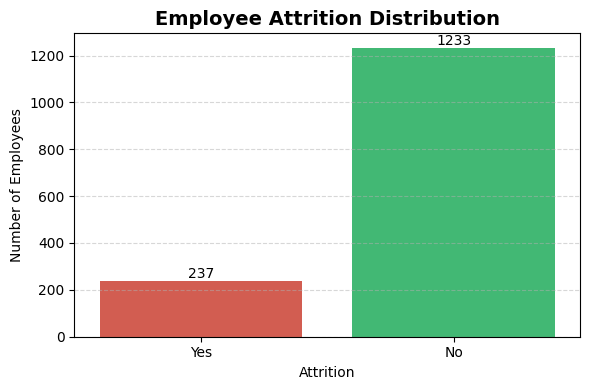

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

palette = ['#E74C3C', '#2ECC71']

plt.figure(figsize=(6,4))

ax = sns.countplot(
    data=df,
    x='Attrition',
    palette=palette,
    order=['Yes', 'No']
)

plt.title("Employee Attrition Distribution", fontsize=14, fontweight='bold')
plt.xlabel("Attrition")
plt.ylabel("Number of Employees")

for container in ax.containers:
    ax.bar_label(container)

plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

### Business Insight

Out of 1,470 employees, **1,231 stayed** while **239 left** the organization, resulting in an attrition rate of approximately **16%**.

Although most employees remain with the company, the employees who leave represent a meaningful business concern. Attrition can increase recruitment costs, onboarding time, and productivity loss. The following analyses investigate the factors associated with employee turnover.

## 5.2 Age Distribution

Age is an important demographic factor that may influence employee experience, career stage, and attrition. This visualization examines the distribution of employee ages across the organization.

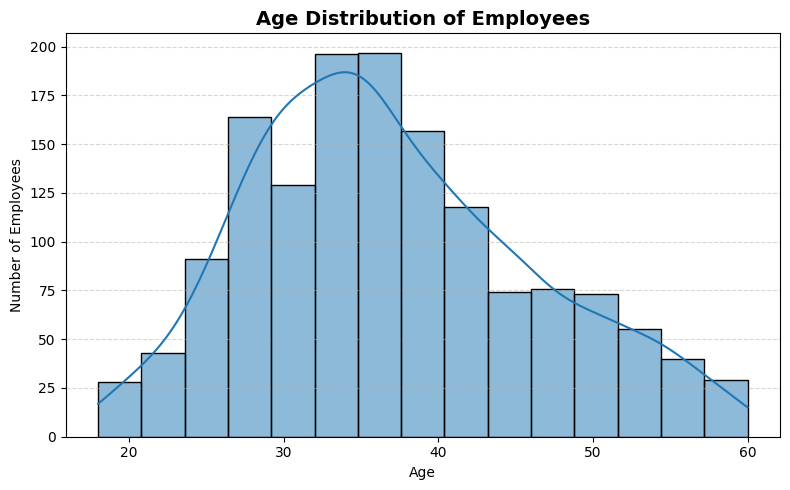

In [ ]:
plt.figure(figsize=(8,5))

sns.histplot(data=df, x='Age', bins=15, kde=True)

plt.title("Age Distribution of Employees", fontsize=14, fontweight='bold')
plt.xlabel("Age")
plt.ylabel("Number of Employees")

plt.grid(axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

### Business Insight

The age distribution shows that most employees are between **30 and 40 years old**, indicating that the organization has a predominantly mid-career workforce.

There are comparatively fewer employees in the younger (below 25) and older (above 50) age groups. This insight helps HR understand the workforce composition and can support planning for recruitment, employee development, and succession planning.

## 5.X Attrition by Overtime

This analysis examines whether employees who work overtime are more likely to leave the organization.

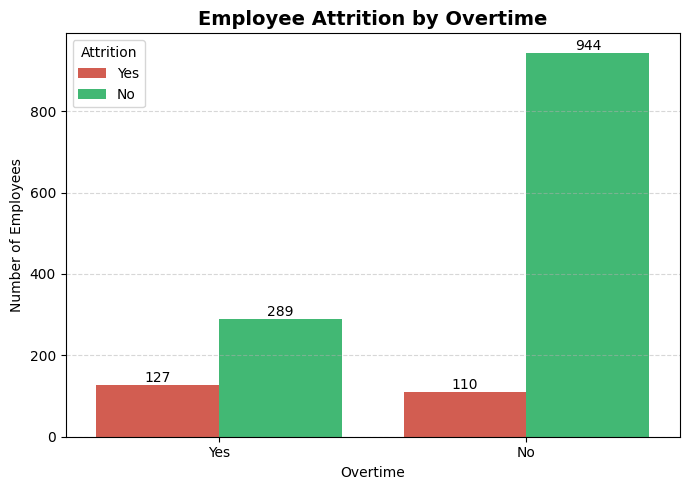

In [ ]:
plt.figure(figsize=(7,5))

palette = ['#E74C3C', '#2ECC71']

ax = sns.countplot(
    data=df,
    x='OverTime',
    hue='Attrition',
    palette=palette
)

plt.title("Employee Attrition by Overtime", fontsize=14, fontweight='bold')
plt.xlabel("Overtime")
plt.ylabel("Number of Employees")

for container in ax.containers:
    ax.bar_label(container)

plt.grid(axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

### Business Insight

Employees who work overtime appear to leave the organization more frequently than those who do not.

This suggests that excessive workload and longer working hours may contribute to employee turnover. HR teams should monitor overtime patterns and ensure employees maintain a healthy work-life balance.

## 5.X Attrition by Department

This analysis compares employee attrition across different departments to identify areas with higher turnover.

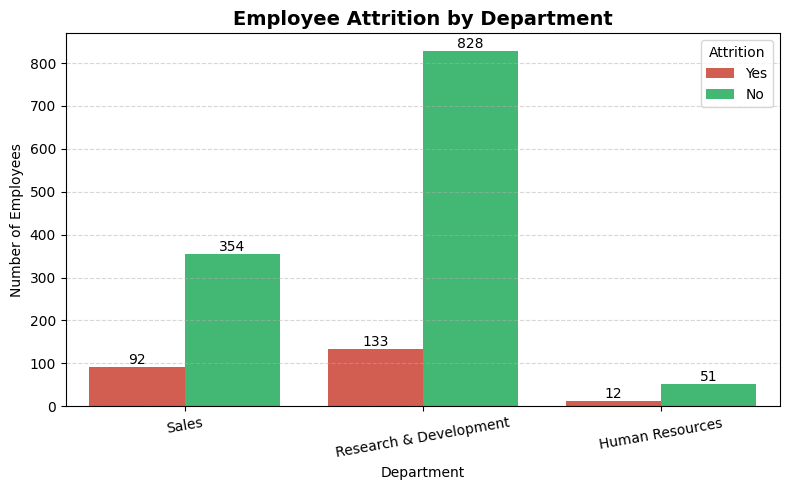

In [ ]:
plt.figure(figsize=(8,5))

palette = ['#E74C3C', '#2ECC71']

ax = sns.countplot(
    data=df,
    x='Department',
    hue='Attrition',
    palette=palette
)

plt.title("Employee Attrition by Department", fontsize=14, fontweight='bold')
plt.xlabel("Department")
plt.ylabel("Number of Employees")

for container in ax.containers:
    ax.bar_label(container)

plt.xticks(rotation=10)

plt.grid(axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

### Business Insight

Employee attrition varies across departments. Comparing the number of employees who left versus those who stayed helps identify departments that may require additional retention efforts.

Departments with consistently higher attrition should be investigated to determine whether workload, management practices, or career growth opportunities are contributing factors.

## 5.X Attrition by Work-Life Balance

This analysis investigates whether employees with different work-life balance ratings experience different levels of attrition.

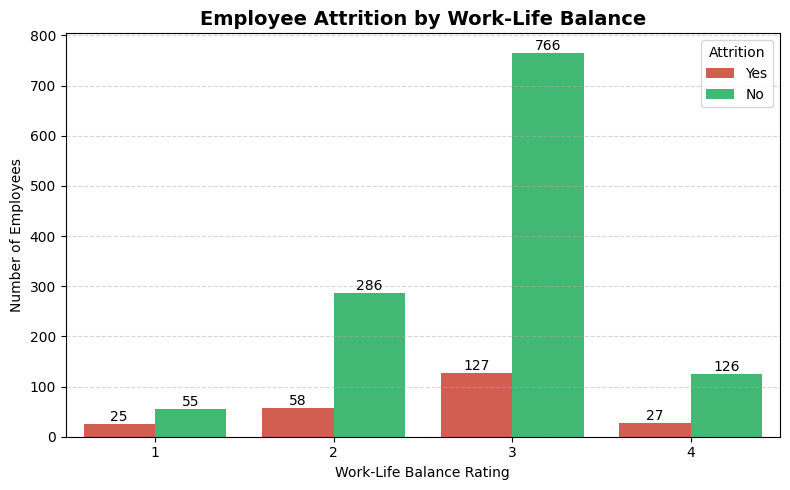

In [ ]:
plt.figure(figsize=(8,5))

palette = ['#E74C3C', '#2ECC71']

ax = sns.countplot(
    data=df,
    x='WorkLifeBalance',
    hue='Attrition',
    palette=palette
)

plt.title("Employee Attrition by Work-Life Balance", fontsize=14, fontweight='bold')
plt.xlabel("Work-Life Balance Rating")
plt.ylabel("Number of Employees")

for container in ax.containers:
    ax.bar_label(container)

plt.grid(axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

### Business Insight

Employees reporting lower work-life balance ratings appear more likely to leave the organization.

This suggests that improving workload management, flexible work arrangements, and employee well-being initiatives may help reduce attrition.

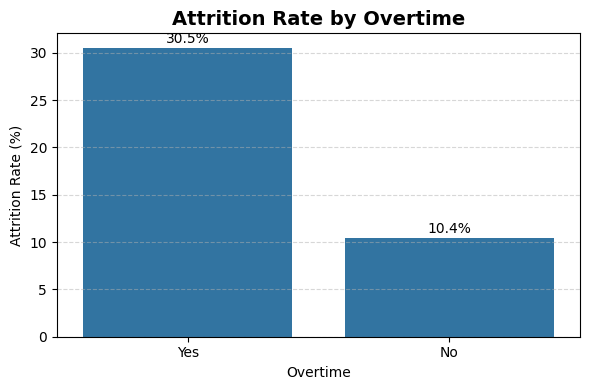

In [ ]:
overtime_attrition = (
    df.groupby('OverTime')['Attrition']
      .apply(lambda x: (x == 'Yes').mean() * 100)
      .sort_values(ascending=False)
)

plt.figure(figsize=(6,4))

ax = sns.barplot(
    x=overtime_attrition.index,
    y=overtime_attrition.values
)

plt.title("Attrition Rate by Overtime", fontsize=14, fontweight='bold')
plt.xlabel("Overtime")
plt.ylabel("Attrition Rate (%)")

for i, value in enumerate(overtime_attrition.values):
    plt.text(i, value + 0.5, f"{value:.1f}%", ha='center')

plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

In [ ]:
import pandas as pd
df = pd.read_csv('HR_Employee_Attrition.csv')
df.head()

,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager,AgeBand
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,...,80,0,8,0,1,6,4,0,5,36-45
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,...,80,1,10,3,3,10,7,1,7,46-60
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,...,80,0,7,3,3,0,0,0,0,36-45
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,...,80,0,8,3,3,8,7,3,0,26-35
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,...,80,1,6,3,3,2,2,2,2,26-35


In [ ]:
print("Shape:", df.shape)
print("\nColumn names:\n", df.columns.tolist())
print("\nMissing values:\n", df.isnull().sum().sum())
print("\nAttrition breakdown:\n", df['Attrition'].value_counts())

Shape: (1470, 36)

Column names:
 ['Age', 'Attrition', 'BusinessTravel', 'DailyRate', 'Department', 'DistanceFromHome', 'Education', 'EducationField', 'EmployeeCount', 'EmployeeNumber', 'EnvironmentSatisfaction', 'Gender', 'HourlyRate', 'JobInvolvement', 'JobLevel', 'JobRole', 'JobSatisfaction', 'MaritalStatus', 'MonthlyIncome', 'MonthlyRate', 'NumCompaniesWorked', 'Over18', 'OverTime', 'PercentSalaryHike', 'PerformanceRating', 'RelationshipSatisfaction', 'StandardHours', 'StockOptionLevel', 'TotalWorkingYears', 'TrainingTimesLastYear', 'WorkLifeBalance', 'YearsAtCompany', 'YearsInCurrentRole', 'YearsSinceLastPromotion', 'YearsWithCurrManager', 'AgeBand']

Missing values:
 0

Attrition breakdown:
 Attrition
No     1233
Yes     237
Name: count, dtype: int64


In [ ]:
drop_cols = ['EmployeeCount', 'StandardHours', 'Over18', 'EmployeeNumber']
df_clean = df.drop(columns=[c for c in drop_cols if c in df.columns])
df_clean['AttritionFlag'] = (df_clean['Attrition'] == 'Yes').astype(int)
print("New shape:", df_clean.shape)
df_clean.head()

New shape: (1470, 33)


,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EnvironmentSatisfaction,Gender,...,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager,AgeBand,AttritionFlag
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,2,Female,...,0,8,0,1,6,4,0,5,36-45,1
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,3,Male,...,1,10,3,3,10,7,1,7,46-60,0
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,4,Male,...,0,7,3,3,0,0,0,0,36-45,1
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,4,Female,...,0,8,3,3,8,7,3,0,26-35,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,Male,...,1,6,3,3,2,2,2,2,26-35,0


In [ ]:
def attrition_rate_by(col):
    return (df_clean.groupby(col)['AttritionFlag']
            .mean().mul(100).round(1).sort_values(ascending=False))

print("Overall attrition rate:", round(df_clean['AttritionFlag'].mean() * 100, 1), "%\n")

print("By Department:\n", attrition_rate_by('Department'), "\n")
print("By OverTime:\n", attrition_rate_by('OverTime'), "\n")
print("By JobRole:\n", attrition_rate_by('JobRole'), "\n")

Overall attrition rate: 16.1 %

By Department:
 Department
Sales                     20.6
Human Resources           19.0
Research & Development    13.8
Name: AttritionFlag, dtype: float64 

By OverTime:
 OverTime
Yes    30.5
No     10.4
Name: AttritionFlag, dtype: float64 

By JobRole:
 JobRole
Sales Representative         39.8
Laboratory Technician        23.9
Human Resources              23.1
Sales Executive              17.5
Research Scientist           16.1
Healthcare Representative     6.9
Manufacturing Director        6.9
Manager                       4.9
Research Director             2.5
Name: AttritionFlag, dtype: float64 



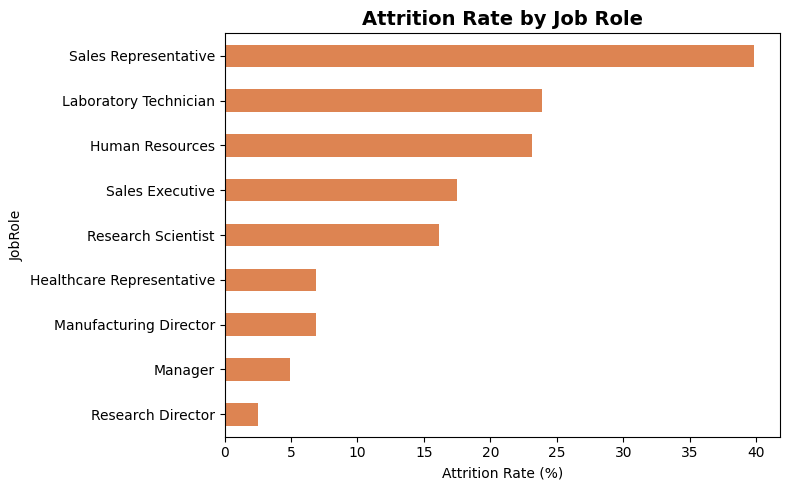

In [ ]:
import matplotlib.pyplot as plt


plt.figure(figsize=(8, 5))
attrition_rate_by('JobRole').plot(kind='barh', color='#DD8452')
plt.xlabel('Attrition Rate (%)')
plt.title("Attrition Rate by Job Role", fontsize=14, fontweight='bold')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

### Business Insight

Sales Representatives experience the highest attrition rate (approximately 40%), followed by Laboratory Technicians and Human Resources employees.

This suggests that HR should prioritize retention initiatives for these job roles, such as reviewing workload, compensation, career progression, and employee engagement programs.

/tmp/ipykernel_696/1901713117.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


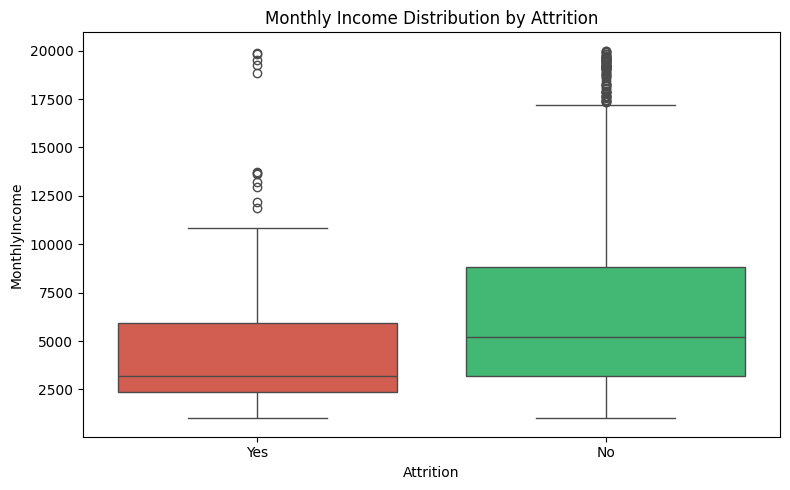

In [ ]:
import seaborn as sns

plt.figure(figsize=(8,5))
sns.boxplot(
    data=df,
    x="Attrition",
    y="MonthlyIncome",
    palette=["#E74C3C", "#2ECC71"]
)
plt.title('Monthly Income Distribution by Attrition')
plt.tight_layout()
plt.show()

### Business Insight

Employees who left the company generally earned lower monthly incomes compared to those who remained.

Although salary is unlikely to be the only factor influencing attrition, the results suggest that compensation may play an important role in employee retention.

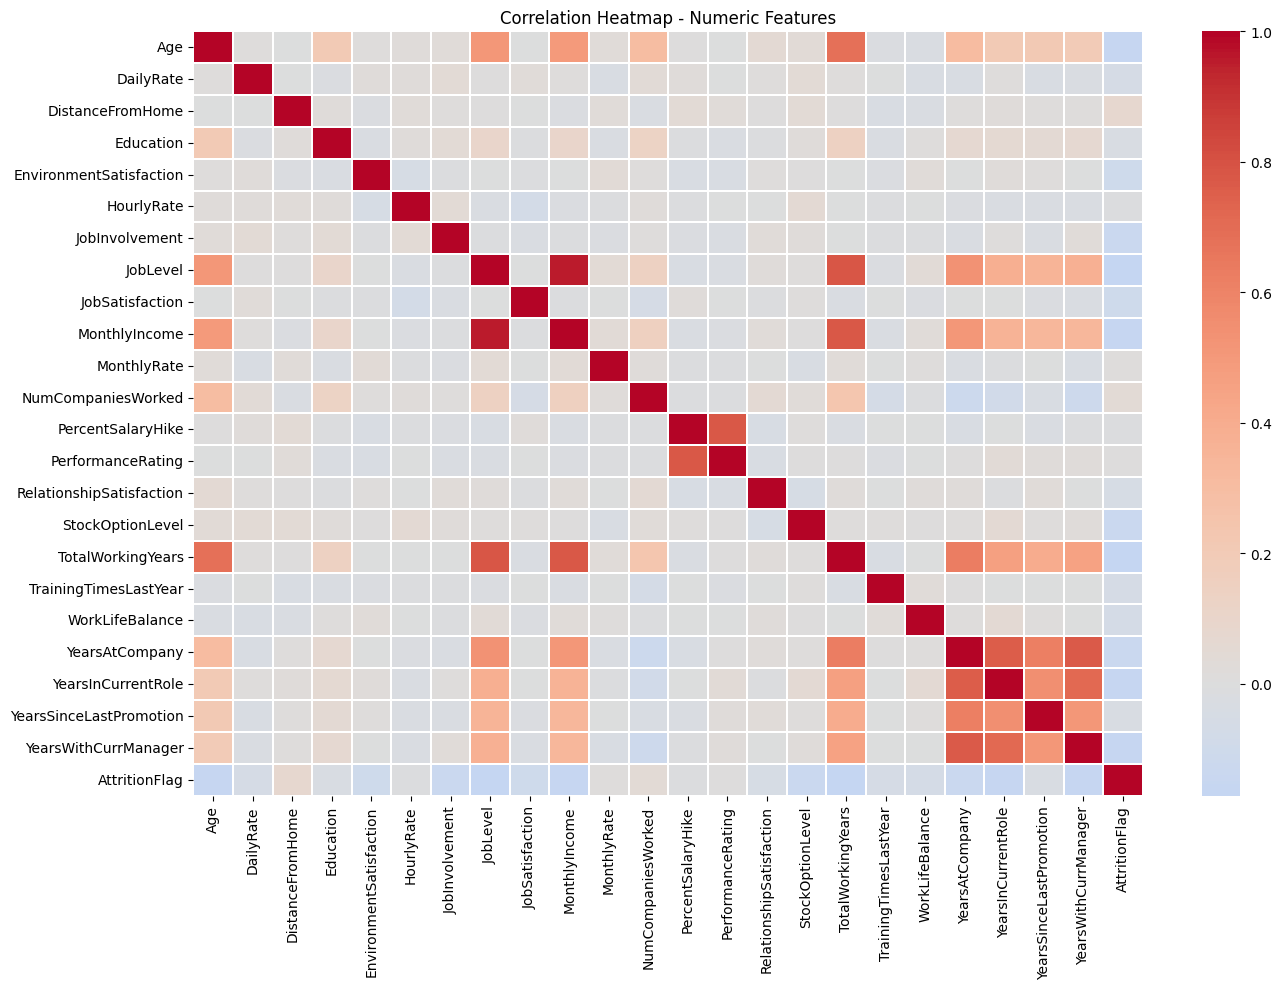

In [ ]:
plt.figure(figsize=(14,10))
numeric_df = df_clean.select_dtypes(include='number')
corr = numeric_df.corr()
sns.heatmap(corr, cmap='coolwarm', center=0, linewidths=0.3)
plt.title('Correlation Heatmap - Numeric Features')
plt.tight_layout()
plt.show()

### Business Insight

Most numerical features show weak correlations with employee attrition, indicating that no single factor independently explains employee turnover.

However, variables such as Monthly Income, Job Level, Total Working Years, and Years at Company exhibit moderate relationships with one another, suggesting that experience and compensation are closely linked.

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

# Copy and encode categorical columns
df_model = df_clean.copy()
cat_cols = df_model.select_dtypes(include='object').columns.tolist()
cat_cols.remove('Attrition')  # we'll handle target separately

le = LabelEncoder()
for col in cat_cols:
    df_model[col] = le.fit_transform(df_model[col])

X = df_model.drop(columns=['Attrition', 'AttritionFlag'])
y = df_model['AttritionFlag']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
print("Train shape:", X_train.shape, "Test shape:", X_test.shape)

Train shape: (1176, 31) Test shape: (294, 31)


In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

model = LogisticRegression(max_iter=1000)
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

print("Accuracy:", round(accuracy_score(y_test, y_pred) * 100, 1), "%")
print("\nClassification Report:\n", classification_report(y_test, y_pred))
print("\nConfusion Matrix:\n", confusion_matrix(y_test, y_pred))

Accuracy: 87.1 %

Classification Report:
               precision    recall  f1-score   support

           0       0.87      1.00      0.93       247
           1       1.00      0.19      0.32        47

    accuracy                           0.87       294
   macro avg       0.93      0.60      0.62       294
weighted avg       0.89      0.87      0.83       294


Confusion Matrix:
 [[247   0]
 [ 38   9]]


/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [ ]:
import pandas as pd

coefficients = pd.DataFrame({
    'Feature': X.columns,
    'Coefficient': model.coef_[0]
}).sort_values(by='Coefficient', ascending=False)

print("Top factors INCREASING attrition risk:\n", coefficients.head(10))
print("\nTop factors DECREASING attrition risk:\n", coefficients.tail(10))

Top factors INCREASING attrition risk:
                     Feature  Coefficient
18                 OverTime     0.353721
14            MaritalStatus     0.285362
28  YearsSinceLastPromotion     0.163195
3                Department     0.116545
17       NumCompaniesWorked     0.114487
20        PerformanceRating     0.082649
26           YearsAtCompany     0.078300
1            BusinessTravel     0.053397
5                 Education     0.047123
8                    Gender     0.044145

Top factors DECREASING attrition risk:
                      Feature  Coefficient
30                   AgeBand    -0.070190
23         TotalWorkingYears    -0.093304
21  RelationshipSatisfaction    -0.104015
25           WorkLifeBalance    -0.114582
27        YearsInCurrentRole    -0.120266
29      YearsWithCurrManager    -0.122220
10            JobInvolvement    -0.193445
13           JobSatisfaction    -0.227770
7    EnvironmentSatisfaction    -0.273892
22          StockOptionLevel    -0.277399


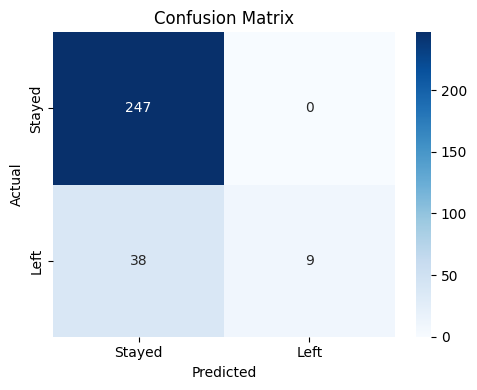

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Stayed', 'Left'], yticklabels=['Stayed', 'Left'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.tight_layout()
plt.show()

<Figure size 1000x1500 with 0 Axes>

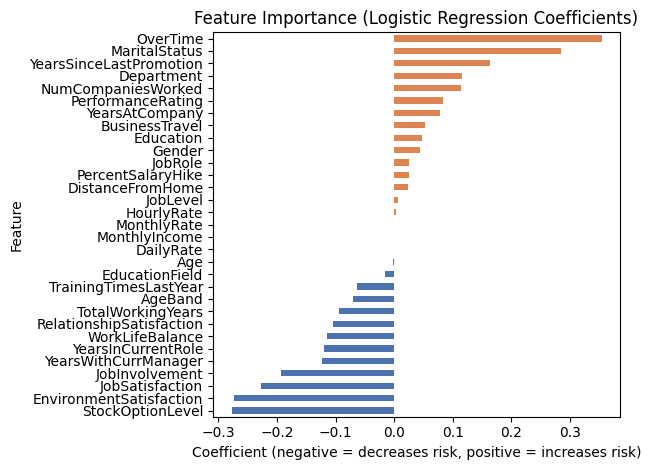

In [ ]:
plt.figure(figsize=(10, 15))
coefficients.sort_values(by='Coefficient').plot(
    x='Feature', y='Coefficient', kind='barh', legend=False,
    color=['#4C72B0' if v < 0 else '#DD8452' for v in coefficients.sort_values(by='Coefficient')['Coefficient']]
)
plt.title('Feature Importance (Logistic Regression Coefficients)')
plt.xlabel('Coefficient (negative = decreases risk, positive = increases risk)')
plt.tight_layout()
plt.show()

# Conclusion

## Key Findings

- The overall employee attrition rate is approximately 16%.
- Sales Representatives experience the highest attrition rate.
- Employees with lower monthly income are more likely to leave.
- Overtime and job role appear to influence employee turnover.
- Most numerical variables individually have weak correlations with attrition.- Model recall for predicting attrition (class 1) was low (19%) due to class imbalance — only ~16% of employees actually left. Future work could address this with class weighting or oversampling (SMOTE).


